In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import nltk, re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

# Load spam dataset
df = pd.read_csv('../data/spam.csv', encoding='latin-1')

# Keep only relevant columns
df = df[['v1', 'v2']]
df.columns = ['label', 'text']

# Encode label: spam=1, ham=0
df['label'] = df['label'].map({'spam': 1, 'ham': 0})

print("Shape:", df.shape)
print("\nClass distribution:")
print(df['label'].value_counts().rename({1:'Spam', 0:'Ham (not spam)'}))

Shape: (5572, 2)

Class distribution:
label
Ham (not spam)    4825
Spam               747
Name: count, dtype: int64


C:\Users\Utkarsh Jain\AppData\Local\Temp\ipykernel_16716\3664685909.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette=['#1D9E75', '#D85A30'])
C:\Users\Utkarsh Jain\AppData\Local\Temp\ipykernel_16716\3664685909.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Ham (not spam)', 'Spam'])


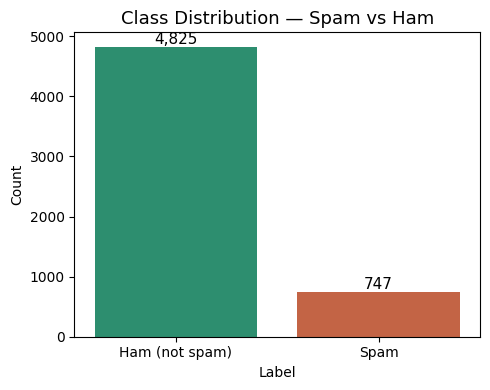

In [2]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x='label', data=df, palette=['#1D9E75', '#D85A30'])
ax.set_xticklabels(['Ham (not spam)', 'Spam'])
ax.set_title('Class Distribution — Spam vs Ham', fontsize=13)
ax.set_xlabel('Label')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.savefig('../data/class_distribution_spam.png', dpi=150)
plt.show()

Average message length:
label
Ham     14.200622
Spam    23.851406
Name: text_length, dtype: float64


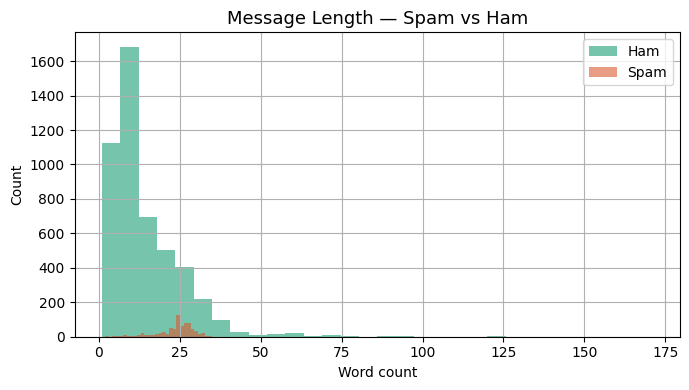

In [3]:
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))

print("Average message length:")
print(df.groupby('label')['text_length'].mean().rename({0:'Ham', 1:'Spam'}))

plt.figure(figsize=(7, 4))
df[df['label']==0]['text_length'].hist(bins=30, alpha=0.6, color='#1D9E75', label='Ham')
df[df['label']==1]['text_length'].hist(bins=30, alpha=0.6, color='#D85A30', label='Spam')
plt.title('Message Length — Spam vs Ham', fontsize=13)
plt.xlabel('Word count')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.savefig('../data/text_length_spam.png', dpi=150)
plt.show()

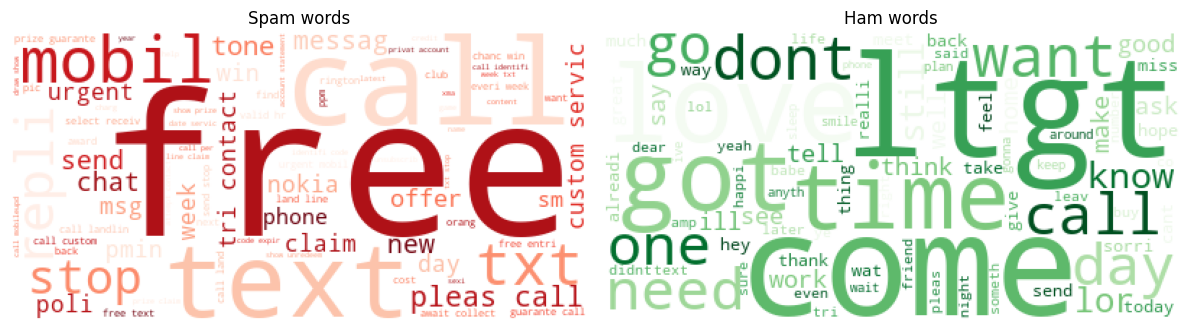

Saved — 5572 rows


In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words and len(w) > 2]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean_text)

# Word clouds
spam_text = ' '.join(df[df['label']==1]['clean_text'])
ham_text  = ' '.join(df[df['label']==0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
WordCloud(background_color='white', colormap='Reds').generate(spam_text) \
    .__class__(background_color='white', colormap='Reds', max_words=80) \
    .generate(spam_text) if False else None

wc_spam = WordCloud(background_color='white', colormap='Reds', max_words=80).generate(spam_text)
wc_ham  = WordCloud(background_color='white', colormap='Greens', max_words=80).generate(ham_text)

axes[0].imshow(wc_spam); axes[0].set_title('Spam words'); axes[0].axis('off')
axes[1].imshow(wc_ham);  axes[1].set_title('Ham words');  axes[1].axis('off')
plt.tight_layout()
plt.savefig('../data/wordclouds_spam.png', dpi=150)
plt.show()

df.to_csv('../data/spam_cleaned.csv', index=False)
print(f"Saved — {len(df)} rows")